# Shape representations and alignment

How much of a measured contour difference comes from pose, sampling or correspondence rather than geometry?

Fall 2024.


## Predict
This is an original synthetic planar example in mm. Predict the effect of translation, rotation and a 10% size change. Record what the lesson allows the fit to remove. The paper route uses the supplied figure/results and the same reasoning.

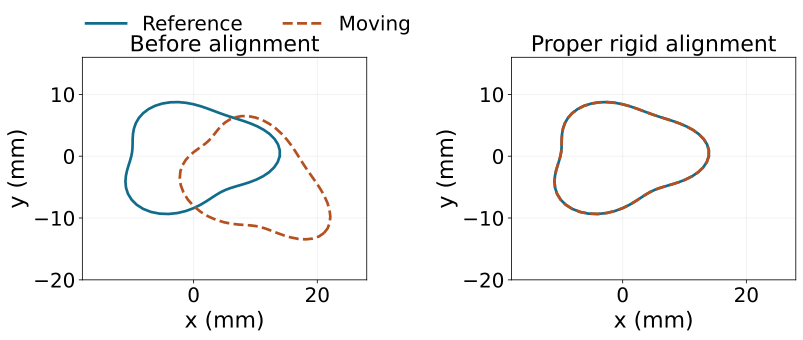

(12.665681274653572, 5.8672193426199026e-15, 0.9999999999999992)

In [1]:
import numpy as np
from demo import curve, rotation, align_rigid, rms, resample_closed, sampling_comparison, run
from IPython.display import SVG, display
report=run()
display(SVG(filename="pose-alignment.svg"))
report["pose_before_mm"], report["pose_after_mm"], report["rotation_determinant"]

## Interpret and modify
Keep the index pairs fixed. Predict whether a size change can be removed by the permitted transform, then choose another positive scale. The determinant check concerns the transformation; the residual concerns the fit.

In [2]:
p=curve(np.arange(48)*2*np.pi/48)
for scale in [1.0,1.10]:
    q=scale*p@rotation(.4)+[6,-2]
    result=align_rigid(p,q)
    print(scale, result["rms_mm"], result["determinant"])

1.0 4.651086118626891e-15 0.9999999999999993
1.1 1.043628382136091 0.9999999999999993


## Predict the sampling comparison
Both samplings trace one analytic contour with the same start and direction. Will adding input vertices repair equal-index correspondence? Compare that prediction with equal polygonal-arclength resampling to a fixed output count.

vertices, index RMS (mm), arclength RMS (mm)
[[1.60000000e+01 4.47088193e+00 2.94384576e-01]
 [3.20000000e+01 4.46927787e+00 8.17084958e-02]
 [6.40000000e+01 4.46927787e+00 2.10701225e-02]
 [1.28000000e+02 4.46927787e+00 5.14261983e-03]]


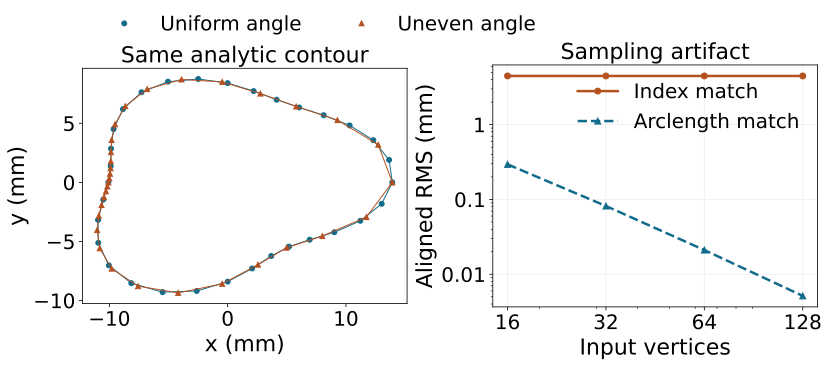

In [3]:
comparison=sampling_comparison((16,32,64,128))
print("vertices, index RMS (mm), arclength RMS (mm)")
print(comparison)
display(SVG(filename="sampling-artifact.svg"))

## Check and report
Change the translation below, rerun, and explain why the residual should remain near zero. Report one fact that this check cannot establish about real anatomy.

In [4]:
shift=np.array([7.,-5.])
check=align_rigid(p,p+shift)
assert check["rms_mm"]<1e-12
assert np.allclose(check["rotation"].T@check["rotation"],np.eye(2))
print("Translation limit RMS (mm):",check["rms_mm"])

Translation limit RMS (mm): 5.280640314064312e-15
